In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
# pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'data' / '2_train_full_clean.parquet')
test = pd.read_parquet(PROJECT_ROOT / 'data' / '2_test_clean.parquet')

print(train.shape, test.shape)

(749609, 34) (186263, 33)


In [2]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

# 종속변수군
target_col = 'target_maxrise_6h'

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]

# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = train.select_dtypes(include='number').columns

assert len(num_cols) == 32, "'num_cols' 개수 이상"
assert (set(train.columns) - set(num_cols)) == {'station_id', 'timestamp'}, "'num_cols' 확인필요"

print(num_cols)  # target_col 포함됨

Index(['wl_t', 'wl_t_minus_1h', 'wl_t_minus_3h', 'wl_t_minus_6h',
       'wl_t_minus_12h', 'wl_t_minus_24h', 'imerg_rain_1h', 'imerg_rain_6h',
       'imerg_rain_24h', 'sfc_rain_1h', 'sfc_rain_6h', 'sfc_rain_24h',
       'radar_reflectivity_mean', 'radar_reflectivity_p95',
       'radar_reflectivity_ge20_fraction', 'cat_area', 'wsarea',
       'mean_elevation', 'mean_slope', 'urban_ratio', 'forest_ratio',
       'stream_order', 'target_maxrise_6h', 'wl_diff_1h', 'wl_diff_3h',
       'wl_diff_6h', 'wl_diff_12h', 'wl_diff_24h', 'imerg_int_1to6h',
       'imerg_int_6to24h', 'sfc_int_1to6h', 'sfc_int_6to24h'],
      dtype='object')


In [3]:
# ============================================================
# 2. 수위변수 및 종속변수간 상관계수
# ============================================================

print("===== 피어슨 상관계수: 수위변수군 =====")
display(
    train[wl_cols + [target_col]]
    .corr(
        method='pearson'
    )
    .round(2)
)
print()

print("===== 스피어만 상관계수: 수위변수군 =====")
display(
    train[wl_cols + [target_col]]
    .corr(
        method='spearman'
    )
    .round(2)
)

===== 피어슨 상관계수: 수위변수군 =====


,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,target_maxrise_6h
wl_t,1.00,1.00,1.00,1.00,1.00,1.00,-0.03
wl_t_minus_1h,1.00,1.00,1.00,1.00,1.00,1.00,-0.03
wl_t_minus_3h,1.00,1.00,1.00,1.00,1.00,1.00,-0.03
wl_t_minus_6h,1.00,1.00,1.00,1.00,1.00,1.00,-0.02
wl_t_minus_12h,1.00,1.00,1.00,1.00,1.00,1.00,-0.03
wl_t_minus_24h,1.00,1.00,1.00,1.00,1.00,1.00,-0.03
target_maxrise_6h,-0.03,-0.03,-0.03,-0.02,-0.03,-0.03,1.00



===== 스피어만 상관계수: 수위변수군 =====


,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,target_maxrise_6h
wl_t,1.00,1.00,0.98,0.96,0.96,0.94,-0.01
wl_t_minus_1h,1.00,1.00,0.99,0.96,0.96,0.94,-0.03
wl_t_minus_3h,0.98,0.99,1.00,0.98,0.96,0.94,-0.03
wl_t_minus_6h,0.96,0.96,0.98,1.00,0.96,0.94,-0.01
wl_t_minus_12h,0.96,0.96,0.96,0.96,1.00,0.97,-0.04
wl_t_minus_24h,0.94,0.94,0.94,0.94,0.97,1.00,-0.03
target_maxrise_6h,-0.01,-0.03,-0.03,-0.01,-0.04,-0.03,1.00


In [4]:
# ============================================================
# 3. 수위 차분변수(wl_diff) 및 종속변수 상관계수
# ============================================================

print("===== 피어슨 상관계수: 수위변수군 =====")
display(
    train[wl_diff_cols + [target_col]]
    .corr(
        method='pearson'
    )
    .round(2)
)
print()

print("===== 스피어만 상관계수: 수위변수군 =====")
display(
    train[wl_diff_cols + [target_col]]
    .corr(
        method='spearman'
    )
    .round(2)
)

===== 피어슨 상관계수: 수위변수군 =====


,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,target_maxrise_6h
wl_diff_1h,1.00,0.78,0.37,0.17,0.08,0.19
wl_diff_3h,0.78,1.00,0.73,0.29,0.19,-0.04
wl_diff_6h,0.37,0.73,1.00,0.48,0.38,-0.31
wl_diff_12h,0.17,0.29,0.48,1.00,0.77,0.09
wl_diff_24h,0.08,0.19,0.38,0.77,1.00,0.07
target_maxrise_6h,0.19,-0.04,-0.31,0.09,0.07,1.00



===== 스피어만 상관계수: 수위변수군 =====


,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,target_maxrise_6h
wl_diff_1h,1.00,0.73,0.53,0.35,0.21,0.39
wl_diff_3h,0.73,1.00,0.76,0.51,0.35,0.33
wl_diff_6h,0.53,0.76,1.00,0.68,0.49,0.22
wl_diff_12h,0.35,0.51,0.68,1.00,0.67,0.19
wl_diff_24h,0.21,0.35,0.49,0.67,1.00,0.13
target_maxrise_6h,0.39,0.33,0.22,0.19,0.13,1.00


In [5]:
# ============================================================
# 3-2. 수위 차분변수(wl_diff)의 구간별 종속변수와의 상관계수
# ============================================================

# 가설: 피어슨, 스피어만 상관계수의 차이가 큰 이유가 구간별 상관계수가 상이한데서 오는게 아닐까?

# 수위 상승, 하강 기준을 수위차분값 0.05, -0.05로 임의로 설정
cond_wl_diff_6h_up = train['wl_diff_6h'] > 0.05
cond_wl_diff_6h_0 = train['wl_diff_6h'].between(-0.05, 0.05)
cond_wl_diff_6h_down = train['wl_diff_6h'] < -0.05

for name, cond in [
    ('wl_diff_6h_up', cond_wl_diff_6h_up),
    ('wl_diff_6h_0', cond_wl_diff_6h_0),
    ('wl_diff_6h_down', cond_wl_diff_6h_down)
]:

    print(f"{name}구간")
    print(f"데이터 개수: {cond.sum()}")
    print(
        f"피어슨 상관계수: "
        f"{
            train.loc[cond, ['wl_diff_6h', 'target_maxrise_6h']]
            .corr(method='pearson')
            .round(2)
            .iloc[0, 1]  # 상관계수 행렬에서 딱 원하는 한가지만 가져오기
        }"
    )

    print(
        f"스피어만 상관계수: "
        f"{
            train.loc[cond, ['wl_diff_6h', 'target_maxrise_6h']]
            .corr(method='spearman')
            .round(2)
            .iloc[0, 1]
        }"
    )
    print()

wl_diff_6h_up구간
데이터 개수: 156450
피어슨 상관계수: 0.0
스피어만 상관계수: 0.05

wl_diff_6h_0구간
데이터 개수: 493644
피어슨 상관계수: 0.05
스피어만 상관계수: 0.22

wl_diff_6h_down구간
데이터 개수: 99515
피어슨 상관계수: -0.8
스피어만 상관계수: -0.05



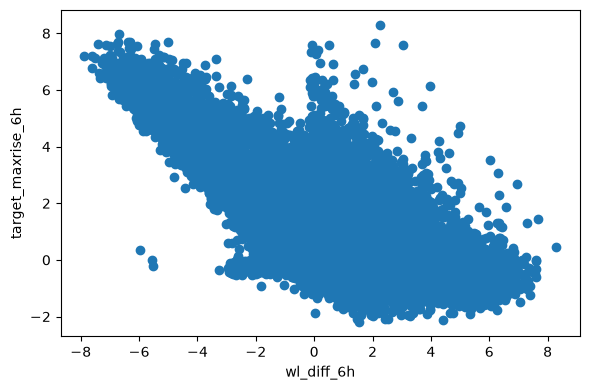

In [6]:
# ============================================================
# 3-3. wl_diff_6h의 수위하강 구간(<-0.05) 산점도 확인
# ============================================================

# y = -x 그래프의 아랫면이 칼로자른듯 비어있는 형태
# wl_t값이 과소하게 측정돼 6시간 전 후와의 값이 벌어진 것으로 추정되는 상황
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    1,
    1,
    figsize = (6, 4)
)

ax.scatter(
    train['wl_diff_6h'],
    train['target_maxrise_6h'])
ax.set_xlabel('wl_diff_6h')
ax.set_ylabel('target_maxrise_6h')

# plt.xlim(0,)
plt.tight_layout()
plt.show()


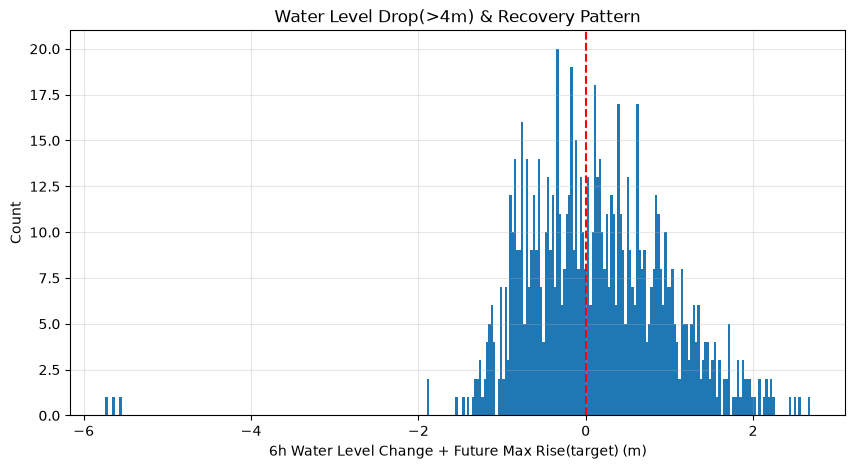

전체 하강 구간: 881개
±0.05m 이내: 4.43%
±0.10m 이내: 8.51%


In [7]:
# ============================================================
# 3-3. wl_diff_6h 기준 수위 하강 후 회복 패턴분포
# ============================================================

# 6h 차분변수 하강구간(<-4) 정의

cond_wl_diff_6h_down3 = train['wl_diff_6h'] < -4

# 수위 하강량 + 향후 6시간 최대 상승량
wl_recovery = (
    train.loc[cond_wl_diff_6h_down3, 'wl_diff_6h']
    + train.loc[cond_wl_diff_6h_down3, 'target_maxrise_6h']
)

# 히스토그램
plt.figure(figsize=(10, 5))

plt.hist(
    wl_recovery,
    bins=300
)

plt.axvline(0, color='red', linestyle='--')

plt.xlabel('6h Water Level Change + Future Max Rise(target) (m)')
plt.ylabel('Count')
plt.title('Water Level Drop(>4m) & Recovery Pattern')
plt.grid(alpha=0.3)
# plt.xlim(-2, 2)   # x축 범위 지정
# plt.ylim(0, 10000)

plt.show()

# 0 근처 집중 정도 확인
print(f"전체 하강 구간: {len(wl_recovery):,}개")
print(f"±0.05m 이내: {(wl_recovery.abs() <= 0.05).mean():.2%}")
print(f"±0.10m 이내: {(wl_recovery.abs() <= 0.10).mean():.2%}")

In [8]:
# ============================================================
# 3-4. Train, Test셋 wl_diff_6h < -4 분포
# ============================================================
# Train, Test 모두 3개 관측소 확인

# 6시간 동안 4m 이상 급하강한 데이터 비교
for name, df in [
    ('Train', train),
    ('Test', test)
]:
    cond = df['wl_diff_6h'] < -4

    print(f"\n{name}")
    print(f"전체 데이터: {len(df):,}개")
    print(f"4m 초과 급하강: {cond.sum():,}개")
    print(f"급하강 비율: {cond.mean():.3%}")
    print(f"해당 관측소: {df.loc[cond, 'station_id'].nunique()}개")


# 4m 초과 급하강 관측소별 발생 횟수

for name, df in [
    ('Train', train),
    ('Test', test)
]:
    print(f"\n{name}")

    print(
        df.loc[
            df['wl_diff_6h'] < -4,
            'station_id'
        ]
        .value_counts()
        .to_string()
    )


Train
전체 데이터: 749,609개
4m 초과 급하강: 881개
급하강 비율: 0.118%
해당 관측소: 4개

Test
전체 데이터: 186,263개
4m 초과 급하강: 242개
급하강 비율: 0.130%
해당 관측소: 3개

Train
station_id
ST0358    382
ST0292    252
ST0326    244
ST0158      3

Test
station_id
ST0358    100
ST0292     75
ST0326     67


In [9]:
# ============================================================
# 3-4. 3개 관측소의 wl_diff_6h 기준 수위 하강 후 회복 패턴분포
# ============================================================
# 3개 관측소 모두 40% 이상 차지

for station in ['ST0358', 'ST0292', 'ST0326']:

    cond = (
        (train['station_id'] == station) &
        (train['wl_diff_6h'] < -4)
    )

    print(f"\n{station}")
    print(f"급하강 사례: {cond.sum():,}개")

    print(
        "하강량과 상승량 차이 ±0.5m 이내 비율:",
        (
            (
                train.loc[cond, 'wl_diff_6h']
                + train.loc[cond, 'target_maxrise_6h']
            ).abs() <= 0.5
        ).mean().round(3)
    )


ST0358
급하강 사례: 382개
하강량과 상승량 차이 ±0.5m 이내 비율: 0.421

ST0292
급하강 사례: 252개
하강량과 상승량 차이 ±0.5m 이내 비율: 0.429

ST0326
급하강 사례: 244개
하강량과 상승량 차이 ±0.5m 이내 비율: 0.488


In [10]:
# ============================================================
# 4. 강우변수 및 종속변수 상관계수
# ============================================================

print("피어슨_상관계수: 강우변수군")
print(
    train[rain_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 강우변수군")
print(
    train[rain_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 강우변수군
	imerg_rain_1h	imerg_rain_6h	imerg_rain_24h	sfc_rain_1h	sfc_rain_6h	sfc_rain_24h	radar_reflectivity_mean	radar_reflectivity_p95	radar_reflectivity_ge20_fraction	target_maxrise_6h
imerg_rain_1h	1.0	0.65	0.4	0.37	0.28	0.19	0.49	0.42	0.47	0.19
imerg_rain_6h	0.65	1.0	0.69	0.43	0.58	0.41	0.5	0.43	0.49	0.2
imerg_rain_24h	0.4	0.69	1.0	0.31	0.51	0.72	0.34	0.31	0.33	0.16
sfc_rain_1h	0.37	0.43	0.31	1.0	0.62	0.39	0.45	0.41	0.42	0.26
sfc_rain_6h	0.28	0.58	0.51	0.62	1.0	0.7	0.37	0.35	0.36	0.24
sfc_rain_24h	0.19	0.41	0.72	0.39	0.7	1.0	0.24	0.25	0.23	0.19
radar_reflectivity_mean	0.49	0.5	0.34	0.45	0.37	0.24	1.0	0.91	0.92	0.19
radar_reflectivity_p95	0.42	0.43	0.31	0.41	0.35	0.25	0.91	1.0	0.81	0.18
radar_reflectivity_ge20_fraction	0.47	0.49	0.33	0.42	0.36	0.23	0.92	0.81	1.0	0.18
target_maxrise_6h	0.19	0.2	0.16	0.26	0.24	0.19	0.19	0.18	0.18	1.0


스피어만_상관계수: 강우변수군
	imerg_rain_1h	imerg_rain_6h	imerg_rain_24h	sfc_rain_1h	sfc_rain_6h	sfc_rain_24h	radar_reflectivity_mean	radar_reflectivity_p9

In [11]:
# ============================================================
# 5. 강우강도 및 종속변수 상관계수
# ============================================================

print("피어슨_상관계수: 강우강도변수군")
print(
    train[rain_int_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 강우강도변수군")
print(
    train[rain_int_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 강우강도변수군
	imerg_int_1to6h	imerg_int_6to24h	sfc_int_1to6h	sfc_int_6to24h	target_maxrise_6h
imerg_int_1to6h	1.0	0.33	0.57	0.19	0.18
imerg_int_6to24h	0.33	1.0	0.34	0.73	0.1
sfc_int_1to6h	0.57	0.34	1.0	0.32	0.2
sfc_int_6to24h	0.19	0.73	0.32	1.0	0.1
target_maxrise_6h	0.18	0.1	0.2	0.1	1.0


스피어만_상관계수: 강우강도변수군
	imerg_int_1to6h	imerg_int_6to24h	sfc_int_1to6h	sfc_int_6to24h	target_maxrise_6h
imerg_int_1to6h	1.0	0.4	0.64	0.2	0.32
imerg_int_6to24h	0.4	1.0	0.5	0.71	0.13
sfc_int_1to6h	0.64	0.5	1.0	0.47	0.32
sfc_int_6to24h	0.2	0.71	0.47	1.0	0.11
target_maxrise_6h	0.32	0.13	0.32	0.11	1.0




In [12]:
# ============================================================
# 6. 유역환경변수 및 종속변수간 상관계수
# ============================================================

print("피어슨_상관계수: 환경변수군")
print(
    train[env_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 환경변수군")
print(
    train[env_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 환경변수군
	cat_area	wsarea	mean_elevation	mean_slope	urban_ratio	forest_ratio	stream_order	target_maxrise_6h
cat_area	1.0	0.58	-0.17	-0.2	0.5	-0.27	0.45	0.03
wsarea	0.58	1.0	-0.19	-0.14	0.17	-0.18	0.74	0.02
mean_elevation	-0.17	-0.19	1.0	0.79	-0.39	0.7	-0.2	-0.04
mean_slope	-0.2	-0.14	0.79	1.0	-0.49	0.94	-0.15	-0.05
urban_ratio	0.5	0.17	-0.39	-0.49	1.0	-0.59	0.06	0.04
forest_ratio	-0.27	-0.18	0.7	0.94	-0.59	1.0	-0.16	-0.06
stream_order	0.45	0.74	-0.2	-0.15	0.06	-0.16	1.0	0.01
target_maxrise_6h	0.03	0.02	-0.04	-0.05	0.04	-0.06	0.01	1.0


스피어만_상관계수: 환경변수군
	cat_area	wsarea	mean_elevation	mean_slope	urban_ratio	forest_ratio	stream_order	target_maxrise_6h
cat_area	1.0	0.21	-0.32	-0.3	0.37	-0.33	0.26	0.04
wsarea	0.21	1.0	-0.26	-0.18	-0.11	-0.17	0.89	0.04
mean_elevation	-0.32	-0.26	1.0	0.88	-0.58	0.85	-0.23	-0.1
mean_slope	-0.3	-0.18	0.88	1.0	-0.65	0.96	-0.19	-0.07
urban_ratio	0.37	-0.11	-0.58	-0.65	1.0	-0.72	-0.05	0.05
forest_ratio	-0.33	-0.17	0.85	0.96	-0.72	1.0	-0.18	-0.08
stream_ord